# 01 · Exploration des données

Premier regard sur la photo des prix du 19 octobre 2026 et sur le fichier national des bornes de recharge.

**Questions**
1. Combien coûte chaque carburant, et quelle est la dispersion entre stations ?
2. Les stations d'autoroute sont-elles plus chères, et de combien ?
3. Le prix varie-t-il selon la géographie et la concurrence locale ?
4. Où sont les bornes de recharge, et quelle puissance proposent-elles ?
5. Quelle confiance accorder aux données (fraîcheur, doublons, valeurs manquantes) ?

Les données viennent de la branche `data` du dépôt. Pour les récupérer : `git fetch origin data && git worktree add data origin/data`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.neighbors import BallTree

DATA = Path("../data")
FIGURES = Path("../rapports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
JOUR = "2026-10-19"

pl.Config.set_tbl_rows(12)
pl.Config.set_tbl_width_chars(140)

# Palette de référence (validée daltonisme) et style sobre
BLEU, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TEXTE, TEXTE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "axes.edgecolor": GRILLE, "axes.labelcolor": TEXTE_2, "axes.titlecolor": TEXTE,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "xtick.color": TEXTE_2, "ytick.color": TEXTE_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def sauver(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png")

## Chargement

In [2]:
dossier = DATA / "prix" / "instantane" / f"date={JOUR}"
stations = pl.read_parquet(dossier / "stations.parquet")
prix = pl.read_parquet(dossier / "prix.parquet")
bornes = pl.read_parquet(DATA / "irve" / f"bornes_{JOUR}.parquet")
print(f"{stations.height:,} stations · {prix.height:,} prix · {bornes.height:,} lignes de bornes")

9,812 stations · 30,504 prix · 157,460 lignes de bornes


## 1. Prix par carburant

In [3]:
ORDRE = ["Gazole", "E10", "SP95", "SP98", "E85", "GPLc"]
resume = (
    prix.group_by("carburant")
    .agg(
        stations=pl.len(),
        mediane=pl.col("prix").median(),
        p10=pl.col("prix").quantile(0.10),
        p90=pl.col("prix").quantile(0.90),
        min=pl.col("prix").min(),
        max=pl.col("prix").max(),
    )
    .with_columns(ecart_p90_p10=pl.col("p90") - pl.col("p10"))
    .sort(pl.col("carburant").replace_strict(ORDRE, list(range(len(ORDRE)))))
)
resume

carburant,stations,mediane,p10,p90,min,max,ecart_p90_p10
str,u32,f64,f64,f64,f64,f64,f64
"""Gazole""",8886,2.369,2.25,2.459,1.381,2.9,0.209
"""E10""",6821,2.179,1.99,2.27,1.88,2.659,0.28
"""SP95""",2717,2.239,1.99,2.302,1.849,2.74,0.312
"""SP98""",6880,2.29,2.188,2.39,1.98,2.88,0.202
"""E85""",3696,0.885,0.859,0.999,0.739,2.249,0.14
"""GPLc""",1504,1.06,0.989,1.156,0.825,2.191,0.167


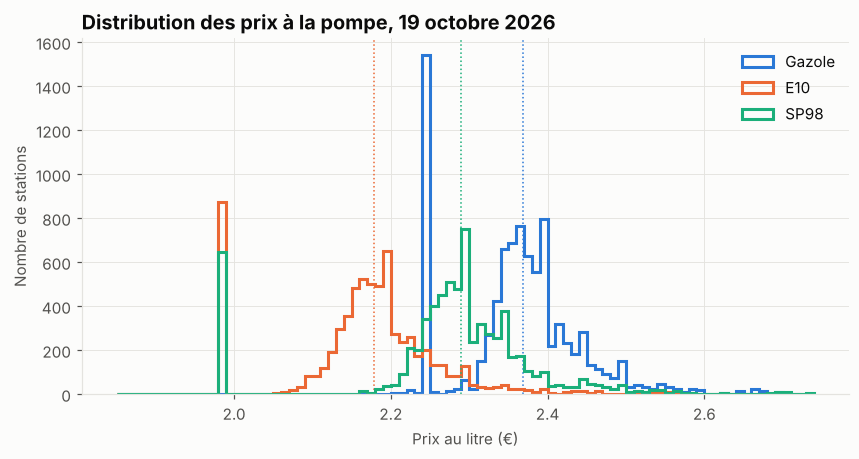

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.2))
principaux = ["Gazole", "E10", "SP98"]
couleurs = [BLEU, ORANGE, AQUA]
bins = np.arange(1.85, 2.75, 0.01)
for carburant, couleur in zip(principaux, couleurs):
    valeurs = prix.filter(carburant=carburant)["prix"].to_numpy()
    ax.hist(valeurs, bins=bins, histtype="step", linewidth=2, color=couleur, label=carburant)
    med = np.median(valeurs)
    ax.axvline(med, color=couleur, linewidth=1, linestyle=":")
ax.set_title("Distribution des prix à la pompe, 19 octobre 2026")
ax.set_xlabel("Prix au litre (€)")
ax.set_ylabel("Nombre de stations")
ax.legend(frameon=False, labelcolor=TEXTE)
sauver(fig, "01_distribution_prix")

Le gazole est plus cher que l'essence (E10, SP98), ce qui est inhabituel en France sur longue période mais cohérent avec les tensions sur le diesel. Entre les 10 % de stations les moins chères et les 10 % les plus chères, l'écart atteint 20 à 30 centimes par litre pour le gazole et les essences : sur un plein de 50 litres, choisir sa station fait gagner 10 à 15 €.

In [5]:
# Les pics de l'histogramme : des prix ronds, identiques partout en France
ronds = {
    "Gazole à 2,25 €": set(prix.filter(carburant="Gazole", prix=2.25)["station_id"]),
    "E10 à 1,99 €": set(prix.filter(carburant="E10", prix=1.99)["station_id"]),
    "SP98 à 1,99 €": set(prix.filter(carburant="SP98", prix=1.99)["station_id"]),
}
gazole_225 = ronds["Gazole à 2,25 €"]
pl.DataFrame([
    {"prix": nom, "stations": len(ids), "dont gazole à 2,25 €": len(ids & gazole_225)}
    for nom, ids in ronds.items()
])

prix,stations,"dont gazole à 2,25 €"
str,i64,i64
"""Gazole à 2,25 €""",1507,1507
"""E10 à 1,99 €""",870,810
"""SP98 à 1,99 €""",646,604


Les pics de l'histogramme correspondent à des prix ronds : 1 507 stations affichent le gazole à exactement 2,25 €, et 810 des 870 stations à 1,99 € pour l'E10 en font partie. Ces stations sont réparties dans toute la France, autoroutes comprises. C'est la signature d'un réseau qui plafonne ses prix au niveau national (hypothèse à confirmer en ajoutant l'enseigne des stations). Pour le modèle de prix, ce sera une variable à part entière : ces stations ne suivent pas la logique locale.

## 2. Autoroute contre route

In [6]:
prix_st = prix.join(stations.select("id", "type_route", "cp", "latitude", "longitude", "services"), left_on="station_id", right_on="id")
autoroute = (
    prix_st.filter(pl.col("carburant").is_in(principaux))
    .group_by("carburant", "type_route")
    .agg(mediane=pl.col("prix").median(), stations=pl.len())
    .pivot(on="type_route", index="carburant", values="mediane")
    .with_columns(surcout=pl.col("autoroute") - pl.col("route"))
)
autoroute

carburant,route,autoroute,surcout
str,f64,f64,f64
"""Gazole""",2.369,2.4605,0.0915
"""SP98""",2.289,2.361,0.072
"""E10""",2.179,2.279,0.1


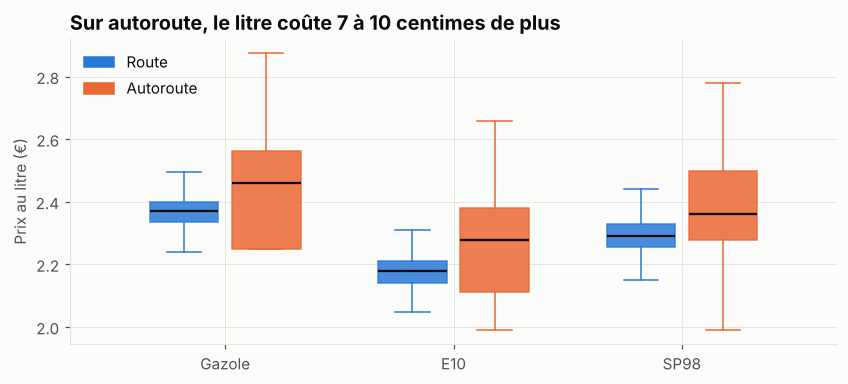

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, carburant in enumerate(principaux):
    for type_route, couleur, decal in [("route", BLEU, -0.18), ("autoroute", ORANGE, 0.18)]:
        valeurs = prix_st.filter(carburant=carburant, type_route=type_route)["prix"].to_numpy()
        bp = ax.boxplot(valeurs, positions=[i + decal], widths=0.3, patch_artist=True,
                        showfliers=False, medianprops={"color": TEXTE, "linewidth": 1.5},
                        boxprops={"facecolor": couleur, "edgecolor": couleur, "alpha": 0.85},
                        whiskerprops={"color": couleur}, capprops={"color": couleur})
ax.set_xticks(range(len(principaux)), principaux)
ax.set_ylabel("Prix au litre (€)")
ax.set_title("Sur autoroute, le litre coûte 7 à 10 centimes de plus")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLEU, label="Route"), Patch(color=ORANGE, label="Autoroute")], frameon=False, labelcolor=TEXTE)
sauver(fig, "02_autoroute")

## 3. Géographie et concurrence locale

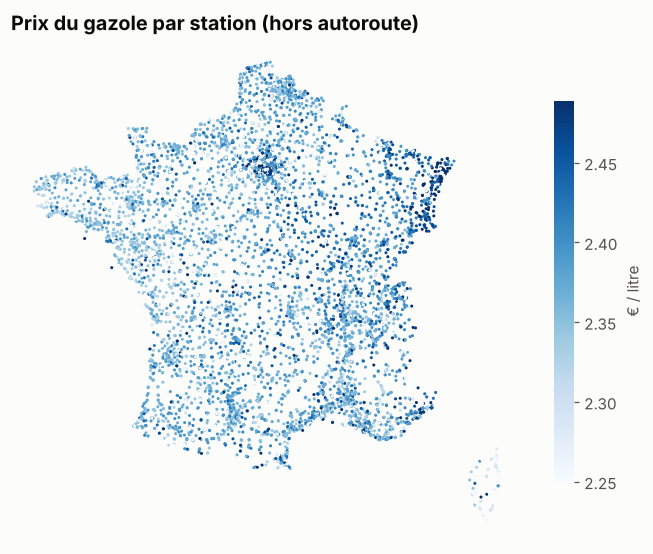

In [8]:
gazole = prix_st.filter(carburant="Gazole", type_route="route").drop_nulls(["latitude", "longitude"])
gazole = gazole.filter(pl.col("latitude").is_between(41, 51.5) & pl.col("longitude").is_between(-5.5, 10))  # métropole

fig, ax = plt.subplots(figsize=(7.5, 7.5))
vmin, vmax = gazole["prix"].quantile(0.05), gazole["prix"].quantile(0.95)
nuage = ax.scatter(gazole["longitude"], gazole["latitude"], c=gazole["prix"], s=4, cmap="Blues",
                   vmin=vmin, vmax=vmax, linewidths=0)
ax.set_aspect(1 / np.cos(np.radians(46.5)))
ax.set_axis_off()
ax.set_title("Prix du gazole par station (hors autoroute)")
barre = fig.colorbar(nuage, ax=ax, shrink=0.6, label="€ / litre")
barre.outline.set_visible(False)
sauver(fig, "03_carte_gazole")

In [9]:
# Prix médian du gazole par département (2 premiers chiffres du code postal ; la Corse 20 regroupe 2A et 2B)
departements = (
    gazole.with_columns(dep=pl.col("cp").str.slice(0, 2))
    .group_by("dep")
    .agg(mediane=pl.col("prix").median(), stations=pl.len())
    .filter(pl.col("stations") >= 20)
    .sort("mediane")
)
pl.concat([departements.head(5), departements.tail(5)])

dep,mediane,stations
str,f64,u32
"""20""",2.25,126
"""85""",2.33,109
"""29""",2.339,134
"""79""",2.339,62
"""44""",2.344,149
"""89""",2.415,70
"""52""",2.419,41
"""57""",2.4275,106
"""68""",2.449,83


In [10]:
# Concurrence : nombre d'autres stations dans un rayon de 5 km
coords = np.radians(gazole.select("latitude", "longitude").to_numpy())
arbre = BallTree(coords, metric="haversine")
voisins = arbre.query_radius(coords, r=5 / 6371, count_only=True) - 1
gazole = gazole.with_columns(concurrents_5km=pl.Series(voisins))

classes = (
    gazole.with_columns(
        classe=pl.when(pl.col("concurrents_5km") == 0).then(pl.lit("0"))
        .when(pl.col("concurrents_5km") <= 2).then(pl.lit("1-2"))
        .when(pl.col("concurrents_5km") <= 5).then(pl.lit("3-5"))
        .when(pl.col("concurrents_5km") <= 10).then(pl.lit("6-10"))
        .otherwise(pl.lit("11+"))
    )
    .group_by("classe")
    .agg(mediane=pl.col("prix").median(), stations=pl.len())
    .sort(pl.col("classe").replace_strict(["0", "1-2", "3-5", "6-10", "11+"], [0, 1, 2, 3, 4]))
)
classes

classe,mediane,stations
str,f64,u32
"""0""",2.379,1481
"""1-2""",2.369,2508
"""3-5""",2.365,1818
"""6-10""",2.359,1323
"""11+""",2.368,1326


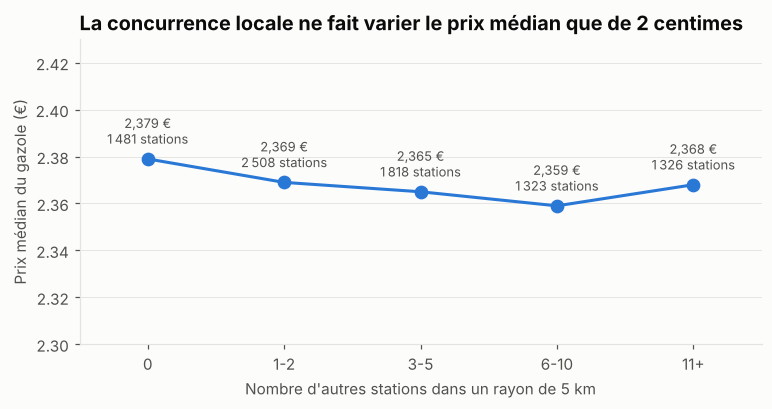

In [11]:
# Points plutôt que barres : l'axe ne part pas de zéro, une barre exagérerait les écarts
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(classes.height)
ax.plot(x, classes["mediane"], color=BLEU, linewidth=2, marker="o", markersize=8)
for xi, (m, n) in enumerate(zip(classes["mediane"], classes["stations"])):
    ax.annotate(f"{m:.3f} €".replace(".", ",") + chr(10) + f"{n:,} stations".replace(",", " "), (xi, m),
                textcoords="offset points", xytext=(0, 10), ha="center", color=TEXTE_2, fontsize=8.5)
ax.set_xticks(x, classes["classe"])
ax.set_ylim(2.30, 2.43)
ax.set_xlim(-0.5, classes.height - 0.5)
ax.set_xlabel("Nombre d'autres stations dans un rayon de 5 km")
ax.set_ylabel("Prix médian du gazole (€)")
ax.set_title("La concurrence locale ne fait varier le prix médian que de 2 centimes")
ax.grid(axis="x", visible=False)
sauver(fig, "04_concurrence")

In [12]:
# Services : les stations avec boutique ou piste poids lourds sont-elles plus chères ?
services_cles = ["Boutique alimentaire", "Piste poids lourds", "Automate CB 24/24", "Lavage automatique", "Restauration à emporter"]
pl.DataFrame([
    {
        "service": s,
        "avec": gazole.filter(pl.col("services").list.contains(s))["prix"].median(),
        "sans": gazole.filter(~pl.col("services").list.contains(s))["prix"].median(),
        "stations_avec": gazole.filter(pl.col("services").list.contains(s)).height,
    }
    for s in services_cles
]).with_columns(ecart=pl.col("avec") - pl.col("sans"))

service,avec,sans,stations_avec,ecart
str,f64,f64,i64,f64
"""Boutique alimentaire""",2.355,2.375,3337,-0.02
"""Piste poids lourds""",2.359,2.376,3385,-0.017
"""Automate CB 24/24""",2.369,2.369,4921,0.0
"""Lavage automatique""",2.359,2.375,2938,-0.016
"""Restauration à emporter""",2.359,2.369,1511,-0.01


Ces écarts sont des corrélations, pas des effets causaux : une station avec automate 24/24 est souvent une station de grande surface, qui pratique des prix bas pour d'autres raisons. Démêler ces facteurs est le rôle de la modélisation (étape 5).

md_placeholder

In [13]:
xy = bornes["coordonneesXY"].str.strip_chars("[] ").str.split(",")
bornes = bornes.with_columns(
    longitude=xy.list.get(0, null_on_oob=True).str.strip_chars().cast(pl.Float64, strict=False),
    latitude=xy.list.get(1, null_on_oob=True).str.strip_chars().cast(pl.Float64, strict=False),
    puissance=pl.col("puissance_nominale").cast(pl.Float64, strict=False),
)
# Un point de recharge peut apparaître plusieurs fois (déclaré par plusieurs sources) : on dédoublonne
pdc = bornes.unique("id_pdc_itinerance", keep="last")
print(f"{bornes.height:,} lignes, {pdc.height:,} points de recharge uniques, {pdc['id_station_itinerance'].n_unique():,} stations")

157,460 lignes, 149,423 points de recharge uniques, 48,279 stations


In [14]:
# Certaines puissances sont déclarées en watts au lieu de kilowatts : on les ramène en kW
pdc = pdc.with_columns(
    puissance=pl.when(pl.col("puissance") > 1000).then(pl.col("puissance") / 1000).otherwise(pl.col("puissance"))
)
paliers = (
    pdc.with_columns(
        palier=pl.when(pl.col("puissance") < 8).then(pl.lit("< 8 kW (lente)"))
        .when(pl.col("puissance") < 23).then(pl.lit("8-22 kW (accélérée)"))
        .when(pl.col("puissance") < 100).then(pl.lit("23-99 kW (rapide)"))
        .when(pl.col("puissance").is_not_null()).then(pl.lit("≥ 100 kW (ultra-rapide)"))
        .otherwise(pl.lit("non renseignée"))
    )
    .group_by("palier").agg(points=pl.len())
    .with_columns(part=(pl.col("points") / pl.col("points").sum() * 100).round(1))
    .sort("points", descending=True)
)
paliers

palier,points,part
str,u32,f64
"""8-22 kW (accélérée)""",76374,51.1
"""< 8 kW (lente)""",30856,20.7
"""≥ 100 kW (ultra-rapide)""",28475,19.1
"""23-99 kW (rapide)""",13718,9.2


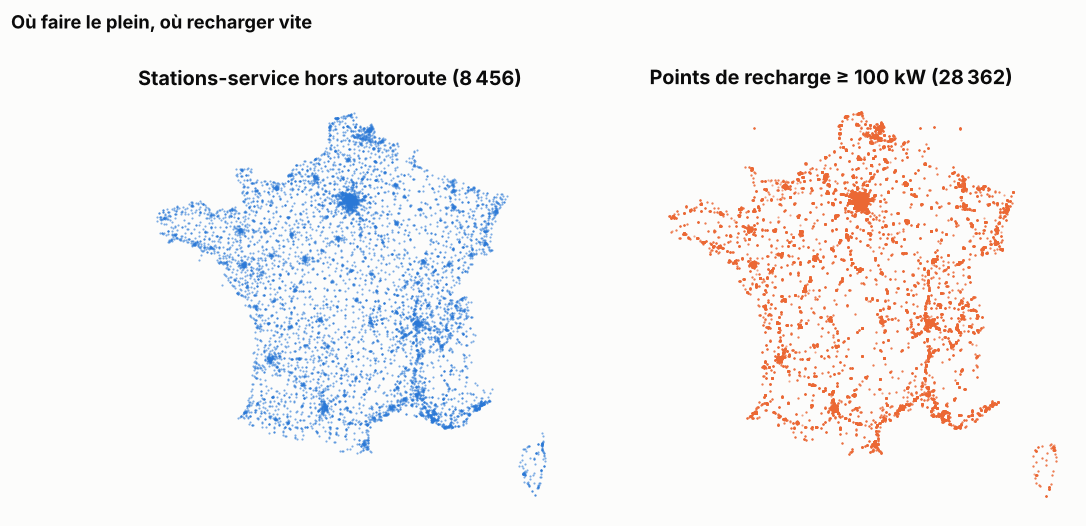

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
metro = pdc.filter(pl.col("latitude").is_between(41, 51.5) & pl.col("longitude").is_between(-5.5, 10))
rapides = metro.filter(pl.col("puissance") >= 100)
for ax, donnees, titre, couleur in [
    (axes[0], gazole, f"Stations-service hors autoroute ({gazole.height:,})".replace(",", " "), BLEU),
    (axes[1], rapides, f"Points de recharge ≥ 100 kW ({rapides.height:,})".replace(",", " "), ORANGE),
]:
    ax.scatter(donnees["longitude"], donnees["latitude"], s=2, color=couleur, linewidths=0, alpha=0.6)
    ax.set_aspect(1 / np.cos(np.radians(46.5)))
    ax.set_axis_off()
    ax.set_title(titre)
fig.suptitle("Où faire le plein, où recharger vite", x=0.02, ha="left", fontweight="bold", color=TEXTE)
sauver(fig, "05_stations_vs_bornes")

In [16]:
# Opérateurs principaux
pdc.group_by("nom_operateur").agg(points=pl.len()).sort("points", descending=True).head(10)

nom_operateur,points
str,u32
"""Bouygues Energies & Services""",14343
"""IZIVIA""",12216
"""Freshmile | FR*FR1""",9452
"""GROUPE INDIGO""",7748
"""Power Dot France""",6611
"""LIDL France""",5562
"""TotalEnergies Charging Service…",4690
"""TESLA France SARL""",4509
"""Greenflux""",4016


## 5. Qualité des données

In [17]:
maintenant = prix["maj"].max()
age = prix.with_columns(age_jours=(maintenant - pl.col("maj")).dt.total_days())
qualite = {
    "prix vieux de plus de 7 jours": age.filter(pl.col("age_jours") > 7).height,
    "prix vieux de plus de 30 jours": age.filter(pl.col("age_jours") > 30).height,
    "stations sans coordonnées": stations.filter(pl.col("latitude").is_null()).height,
    "stations sans aucun prix": stations.join(prix, left_on="id", right_on="station_id", how="anti").height,
    "lignes IRVE en double (même point de recharge)": bornes.height - pdc.height,
    "points de recharge sans code commune": pdc.filter(pl.col("code_insee_commune").is_null()).height,
    "points de recharge sans puissance": pdc.filter(pl.col("puissance").is_null()).height,
    "points de recharge > 400 kW (suspects)": pdc.filter(pl.col("puissance") > 400).height,
}
pl.DataFrame({"contrôle": list(qualite), "nombre": list(qualite.values())})

contrôle,nombre
str,i64
"""prix vieux de plus de 7 jours""",6942
"""prix vieux de plus de 30 jours""",1561
"""stations sans coordonnées""",0
"""stations sans aucun prix""",620
"""lignes IRVE en double (même po…",8037
"""points de recharge sans code c…",58759
"""points de recharge sans puissa…",0
"""points de recharge > 400 kW (s…",361


## À retenir

- La photo du jour suffit pour décrire la géographie des prix, mais pas leur dynamique : l'étape suivante est de charger l'historique annuel (`carburants annee 2025`) pour étudier l'évolution dans le temps et la transmission du prix du pétrole.
- Une part importante des stations (environ 1 500) applique des prix ronds identiques dans toute la France, probablement un plafonnement par une même enseigne.
- L'écart autoroute / route (7 à 10 centimes) et la géographie (près de 25 centimes entre départements extrêmes) sont nets ; la concurrence locale, à l'inverse, pèse peu.
- Près d'un prix sur quatre n'a pas été mis à jour depuis plus de 7 jours : pour les analyses temporelles, il faudra pondérer ou filtrer selon la fraîcheur.
- Près de 40 % des points de recharge n'ont pas de code commune : il faudra le recalculer à partir des coordonnées avant de comparer les territoires.
- Le fichier des bornes demande aussi un dédoublonnage (8 000 lignes en double) et une correction des puissances déclarées en watts.
- Le flux des prix ne donne pas l'enseigne de la station (Total, Leclerc...) ; il faudra l'enrichir, par exemple avec OpenStreetMap, pour isoler l'effet « grande surface ».